# Parte C: riesgo de quiebre

## 0. Preparación de datos

Cada fila es un SKU y bodega. Se predice si el stock baja a la mitad o menos del nivel del 21 en algún día del 22 al 28 de agosto. Incluye agotamiento.

Solo se usan ventas e inventario hasta el 21. riesgo_quiebre es la respuesta e id_combo es el identificador. Ninguno entra como variable del modelo.

Un evento no alertado cuesta Q1,500 y una falsa alerta Q150.


In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path("../datos")

# Se conserva el texto original para revisar blancos y posibles referencias N/A.
etiquetas = pd.read_csv(
    data_dir / "etiquetas_train.csv",
    dtype={"id_combo": str, "SKU": str, "CodigoAlmacen": str},
    keep_default_na=False
)
combos = pd.read_csv(
    data_dir / "combos_a_predecir.csv",
    dtype={"id_combo": str, "SKU": str, "CodigoAlmacen": str},
    keep_default_na=False
)

display(etiquetas.head())
display(combos.head())


,id_combo,SKU,CodigoAlmacen,riesgo_quiebre
0,C0001,0201-004132,GT1SERV,0
1,C0005,13509-132,GT1SERV,0
2,C0006,2501-001011,GT1SERV,0
3,C0007,2501-001035,GT1SERV,0
4,C0008,3001-002871,GT1SERV,0


,id_combo,SKU,CodigoAlmacen
0,C0002,12555601,GT1COMER
1,C0003,13509-132,GT1CEDI
2,C0004,13509-132,GT1COMER
3,C0012,AGE83X/XAP,GT2CEDI
4,C0013,AH94-00022W,GT1SERV


In [2]:
print("Entrenamiento:", etiquetas.shape)
print("Predicción:", combos.shape)

print("IDs repetidos en entrenamiento:", etiquetas.duplicated("id_combo").sum())
print("IDs repetidos en predicción:", combos.duplicated("id_combo").sum())

print("Pares repetidos en entrenamiento:",
      etiquetas.duplicated(["SKU", "CodigoAlmacen"]).sum())
print("Pares repetidos en predicción:",
      combos.duplicated(["SKU", "CodigoAlmacen"]).sum())

print("Valores nulos en entrenamiento:")
display(etiquetas.isna().sum())
print("Valores nulos en predicción:")
display(combos.isna().sum())


Entrenamiento: (916, 4)
Predicción: (392, 3)
IDs repetidos en entrenamiento: 0
IDs repetidos en predicción: 0
Pares repetidos en entrenamiento: 0
Pares repetidos en predicción: 0
Valores nulos en entrenamiento:


id_combo          0
SKU               0
CodigoAlmacen     0
riesgo_quiebre    0
dtype: int64

Valores nulos en predicción:


id_combo         0
SKU              0
CodigoAlmacen    0
dtype: int64

In [3]:
for nombre, tabla in [("etiquetas", etiquetas), ("combos", combos)]:
    print(nombre)
    print("IDs vacíos:", tabla["id_combo"].str.strip().eq("").sum())
    print("SKUs vacíos:", tabla["SKU"].str.strip().eq("").sum())
    print("SKUs N/A:", tabla["SKU"].str.strip().str.upper().eq("N/A").sum())
    print("Bodegas vacías:", tabla["CodigoAlmacen"].str.strip().eq("").sum())


etiquetas
IDs vacíos: 0
SKUs vacíos: 0
SKUs N/A: 0
Bodegas vacías: 0
combos
IDs vacíos: 0
SKUs vacíos: 0
SKUs N/A: 0
Bodegas vacías: 0


Un ID único no garantiza que el par SKU y bodega sea único. Se revisan ambos. También se compara si el mismo par aparece en entrenamiento y predicción, aunque tenga otro ID.


In [4]:
print("IDs compartidos:",
      etiquetas["id_combo"].isin(combos["id_combo"]).sum())

pares_compartidos = etiquetas.merge(
    combos,
    on=["SKU", "CodigoAlmacen"],
    how="inner",
    suffixes=("_train", "_predecir")
)

print("Coincidencias de SKU y bodega:", len(pares_compartidos))
display(pares_compartidos)


IDs compartidos: 0
Coincidencias de SKU y bodega: 0


,id_combo_train,SKU,CodigoAlmacen,riesgo_quiebre,id_combo_predecir


In [5]:
distribucion_objetivo = etiquetas["riesgo_quiebre"].value_counts().sort_index()
display(distribucion_objetivo)

print("Porcentaje de casos positivos:",
      etiquetas["riesgo_quiebre"].eq(1).mean() * 100)

print("Valores del objetivo:", etiquetas["riesgo_quiebre"].unique())
assert etiquetas["riesgo_quiebre"].isin([0, 1]).all()

display(pd.crosstab(etiquetas["CodigoAlmacen"], etiquetas["riesgo_quiebre"]))
print("Columnas de entrenamiento:", etiquetas.columns.tolist())
print("Columnas de predicción:", combos.columns.tolist())


riesgo_quiebre
0    841
1     75
Name: count, dtype: int64

Porcentaje de casos positivos: 8.187772925764191
Valores del objetivo: [0 1]


riesgo_quiebre,0,1
CodigoAlmacen,,
GT1B2B,1,3
GT1CEDI,252,19
GT1COMER,403,2
GT1SERV,122,44
GT2CEDI,49,4
GT2SERV,1,0
GT3CEDI,3,1
GT3COMER,8,2
GT3SERV,2,0


Columnas de entrenamiento: ['id_combo', 'SKU', 'CodigoAlmacen', 'riesgo_quiebre']
Columnas de predicción: ['id_combo', 'SKU', 'CodigoAlmacen']


### Estructura de los datos

Hay 916 pares con respuesta conocida y 392 por predecir. Las etiquetas tienen 75 positivos. No hay IDs ni pares repetidos y no hay pares compartidos entre ambos archivos.

No hay fechas por fila. id_combo no se usa como fecha y no se asume que las etiquetas vienen de varias semanas.


## 1. Variables a partir de ventas e inventario

Se agrupa por SKU y bodega, usando datos del 1 al 21. Se incluyen las bodegas de servicio porque también aparecen en las listas de C.

El stock físico es la referencia del objetivo. El disponible descuenta lo comprometido. Los pedidos pendientes quedan aparte porque no se conoce cuándo llegan.

Las cantidades facturadas positivas aproximan demanda. No se restan créditos porque no todos representan devoluciones físicas.


In [6]:
resultados_dir = Path("resultados")
resultados_dir.mkdir(exist_ok=True)

facturas_encabezado = pd.read_parquet(data_dir / "oinv.parquet")
facturas_detalle = pd.read_parquet(data_dir / "inv1.parquet")
catalogo_productos = pd.read_parquet(data_dir / "oitm.parquet")
inventario_diario = pd.read_parquet(data_dir / "inventario_regional.parquet")

inventario_diario = inventario_diario.loc[
    inventario_diario["DataMartDate"].ge("2026-08-01")
    & inventario_diario["DataMartDate"].lt("2026-08-22")
].copy()

catalogo_priorizado = (
    catalogo_productos.assign(
        prioridad_segmento=(
            catalogo_productos["U_Segmento"].isna()
            | catalogo_productos["U_Segmento"].eq("SIN SEGMENTO")
        ).astype(int)
    )
    .sort_values(["ItemCode", "prioridad_segmento", "U_Segmento"])
    .drop_duplicates("ItemCode")
)

mapa_productos = catalogo_priorizado[["ItemCode", "InvntryUom"]].copy()
mapa_productos.loc[
    mapa_productos["InvntryUom"].str.strip().str.upper().eq("N/A"),
    "InvntryUom"
] = None

pares_modelo = pd.concat([
    etiquetas[["id_combo", "SKU", "CodigoAlmacen"]],
    combos[["id_combo", "SKU", "CodigoAlmacen"]]
], ignore_index=True)

assert not pares_modelo.duplicated(["SKU", "CodigoAlmacen"]).any()


In [7]:
ventas_modelo = (
    facturas_detalle
    .merge(facturas_encabezado, on="DocEntry", validate="many_to_one")
    .merge(mapa_productos, on="ItemCode", how="left", validate="many_to_one")
    .rename(columns={"InvntryUom": "SKU", "WhsCode": "CodigoAlmacen"})
)

ventas_modelo = ventas_modelo.loc[
    ventas_modelo["Canceled"].eq("N")
    & ventas_modelo["DocDate"].ge("2026-08-01")
    & ventas_modelo["DocDate"].lt("2026-08-22")
    & ventas_modelo["SKU"].notna()
    & ventas_modelo["CodigoAlmacen"].notna()
    & ventas_modelo["Quantity"].gt(0)
].copy()

ventas_21 = (
    ventas_modelo.groupby(["SKU", "CodigoAlmacen"], as_index=False)
    .agg(unidades_21_dias=("Quantity", "sum"))
)

ventas_7 = (
    ventas_modelo.loc[ventas_modelo["DocDate"].ge("2026-08-15")]
    .groupby(["SKU", "CodigoAlmacen"], as_index=False)
    .agg(unidades_7_dias=("Quantity", "sum"))
)


In [8]:
inventario_dia = (
    inventario_diario.loc[
        inventario_diario["SKU"].notna()
        & inventario_diario["SKU"].str.strip().str.upper().ne("N/A")
    ]
    .groupby(["SKU", "CodigoAlmacen", "DataMartDate"], as_index=False)
    .agg(
        stock=("sum_Stock", "sum"),
        comprometido=("sum_Comprometido", "sum"),
        pedido=("sum_Pedido", "sum")
    )
)

stock_21 = inventario_dia.loc[
    inventario_dia["DataMartDate"].eq("2026-08-21"),
    ["SKU", "CodigoAlmacen", "stock", "comprometido", "pedido"]
].rename(columns={
    "stock": "stock_21",
    "comprometido": "comprometido_21",
    "pedido": "pedido_21"
})

stock_14 = inventario_dia.loc[
    inventario_dia["DataMartDate"].eq("2026-08-14"),
    ["SKU", "CodigoAlmacen", "stock"]
].rename(columns={"stock": "stock_14"})

cobertura_inventario = (
    inventario_dia.groupby(["SKU", "CodigoAlmacen"], as_index=False)
    .agg(dias_con_inventario=("DataMartDate", "nunique"))
)


In [9]:
variables = (
    pares_modelo
    .merge(stock_21, on=["SKU", "CodigoAlmacen"], how="left", validate="one_to_one")
    .merge(stock_14, on=["SKU", "CodigoAlmacen"], how="left", validate="one_to_one")
    .merge(cobertura_inventario, on=["SKU", "CodigoAlmacen"], how="left", validate="one_to_one")
    .merge(ventas_21, on=["SKU", "CodigoAlmacen"], how="left", validate="one_to_one")
    .merge(ventas_7, on=["SKU", "CodigoAlmacen"], how="left", validate="one_to_one")
)

# Sin coincidencia en ventas significa sin unidades facturadas registradas.
variables["unidades_21_dias"] = variables["unidades_21_dias"].fillna(0)
variables["unidades_7_dias"] = variables["unidades_7_dias"].fillna(0)

variables["stock_disponible_21"] = (
    variables["stock_21"] - variables["comprometido_21"]
).clip(lower=0)

variables["demanda_diaria_7"] = variables["unidades_7_dias"] / 7
variables["sin_ventas_7"] = variables["unidades_7_dias"].eq(0).astype(int)
variables["stock_14_desconocido"] = variables["stock_14"].isna().astype(int)
variables["stock_21_desconocido"] = variables["stock_21"].isna().astype(int)

variables["dias_cobertura_7"] = float("nan")
con_demanda = variables["demanda_diaria_7"].gt(0)
variables.loc[con_demanda, "dias_cobertura_7"] = (
    variables.loc[con_demanda, "stock_disponible_21"]
    / variables.loc[con_demanda, "demanda_diaria_7"]
)

variables["variacion_stock_7_pct"] = float("nan")
stock_anterior_valido = variables["stock_14"].gt(0)
variables.loc[stock_anterior_valido, "variacion_stock_7_pct"] = (
    (variables.loc[stock_anterior_valido, "stock_21"]
     - variables.loc[stock_anterior_valido, "stock_14"])
    / variables.loc[stock_anterior_valido, "stock_14"] * 100
)

display(variables.head())


,id_combo,SKU,CodigoAlmacen,stock_21,comprometido_21,pedido_21,stock_14,dias_con_inventario,unidades_21_dias,unidades_7_dias,stock_disponible_21,demanda_diaria_7,sin_ventas_7,stock_14_desconocido,stock_21_desconocido,dias_cobertura_7,variacion_stock_7_pct
0,C0001,0201-004132,GT1SERV,8,0,0,8.0,21,3.0,0.0,8,0.000000,1,0,0,NaN,0.000000
1,C0005,13509-132,GT1SERV,12,0,0,16.0,21,8.0,4.0,12,0.571429,0,0,0,21.0,-25.000000
2,C0006,2501-001011,GT1SERV,2,0,0,2.0,21,1.0,0.0,2,0.000000,1,0,0,NaN,0.000000
3,C0007,2501-001035,GT1SERV,1,0,0,1.0,21,1.0,0.0,1,0.000000,1,0,0,NaN,0.000000
4,C0008,3001-002871,GT1SERV,8,0,0,7.0,21,2.0,0.0,8,0.000000,1,0,0,NaN,14.285714


### Explicación de cada variable

| Variable | Qué mide |
| --- | --- |
| stock_21 | Stock físico al cierre del 21, que es la referencia del evento a predecir. |
| comprometido_21 | Unidades ya comprometidas, que pueden reducir el stock libre. |
| pedido_21 | Unidades pedidas pendientes, como señal de posible reposición sin asumir llegada. |
| stock_disponible_21 | Stock físico menos comprometido, con mínimo cero. |
| unidades_7_dias | Unidades facturadas del 15 al 21, como señal de demanda reciente. |
| unidades_21_dias | Unidades facturadas del 1 al 21, para observar el período completo. |
| demanda_diaria_7 | Unidades de los últimos siete días divididas entre siete. |
| dias_cobertura_7 | Stock disponible dividido entre demanda diaria reciente, para comparar inventario con ventas. |
| sin_ventas_7 | Vale 1 si no se registraron unidades facturadas en los últimos siete días. |
| stock_14 | Stock físico observado el 14, para comparar con el corte sin usar datos futuros. |
| variacion_stock_7_pct | Cambio porcentual del stock entre el 14 y el 21, incluyendo entradas y salidas. |
| dias_con_inventario | Días con observaciones del 1 al 21, como señal de cobertura de los datos. |
| stock_14_desconocido | Vale 1 si falta la observación del 14 y no se puede confirmar el cambio semanal. |
| stock_21_desconocido | Vale 1 si falta el stock al corte y no debe interpretarse como cero. |

La variación de stock no mide solo consumo, también refleja entradas y traslados. Una fecha ausente queda desconocida. La cobertura sin ventas recientes queda sin calcular, acompañada del indicador sin_ventas_7. Los modelos rellenan los faltantes usando solo entrenamiento. La columna desconocido permite distinguir un dato ausente de un valor observado.


In [10]:
columnas_disponibles = [
    "stock_21", "comprometido_21", "pedido_21", "stock_disponible_21",
    "unidades_7_dias", "unidades_21_dias", "demanda_diaria_7",
    "dias_cobertura_7", "sin_ventas_7", "stock_14",
    "variacion_stock_7_pct", "dias_con_inventario",
    "stock_14_desconocido", "stock_21_desconocido"
]

variables_train = etiquetas.merge(
    variables, on=["id_combo", "SKU", "CodigoAlmacen"],
    how="left", validate="one_to_one"
)
variables_predecir = combos.merge(
    variables, on=["id_combo", "SKU", "CodigoAlmacen"],
    how="left", validate="one_to_one"
)

assert len(variables_train) == len(etiquetas)
assert len(variables_predecir) == len(combos)
assert "riesgo_quiebre" not in columnas_disponibles
assert "id_combo" not in columnas_disponibles

print("Entrenamiento:", len(variables_train))
print("Predicción:", len(variables_predecir))
print("Variables disponibles:", len(columnas_disponibles))
print("Pares sin stock al corte:", variables["stock_21_desconocido"].sum())
print("Pares sin stock el 14:", variables["stock_14_desconocido"].sum())

display(variables[columnas_disponibles].isna().sum())
display(variables["dias_con_inventario"].value_counts().sort_index())

variables_train.to_csv(resultados_dir / "c_variables_train.csv", index=False)
variables_predecir.to_csv(resultados_dir / "c_variables_predecir.csv", index=False)


Entrenamiento: 916
Predicción: 392
Variables disponibles: 14
Pares sin stock al corte: 0
Pares sin stock el 14: 19


stock_21                   0
comprometido_21            0
pedido_21                  0
stock_disponible_21        0
unidades_7_dias            0
unidades_21_dias           0
demanda_diaria_7           0
dias_cobertura_7         576
sin_ventas_7               0
stock_14                  19
variacion_stock_7_pct     19
dias_con_inventario        0
stock_14_desconocido       0
stock_21_desconocido       0
dtype: int64

dias_con_inventario
1       3
2       1
3       1
4       3
5       1
10      8
11      1
14      5
15     14
16      9
17     14
18    402
19      6
20     12
21    828
Name: count, dtype: int64

### Variables para los modelos

Se construyeron 14 columnas para revisar los datos y se usan ocho en ambos modelos. Se eligieron por su significado, antes de comparar resultados.

Se usan stock al 21, comprometido, pedido, unidades vendidas en 7 y 21 días, cambio semanal de stock, días con inventario e indicador de stock anterior desconocido.

Se dejan fuera columnas que repiten información, como ventas de siete días y su promedio diario. Los IDs y la respuesta no son predictores.


## 2. Modelo base simple

Se usa regresión logística como referencia. Aprende una relación entre las ocho variables y la probabilidad de quiebre.

Antes de entrenar se separan los datos. Cada SKU queda en un solo conjunto, aunque tenga varias bodegas. Se reserva cerca de 20% de los SKUs para prueba y 25% de los restantes para validación. El resto se usa para entrenar.

GroupShuffleSplit separa productos completos. split devuelve las posiciones de las filas y next toma la única separación solicitada. iloc usa esas posiciones para formar cada conjunto.


In [11]:
from sklearn.model_selection import GroupShuffleSplit

separar_prueba = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
indices_desarrollo, indices_prueba = next(
    separar_prueba.split(variables_train, groups=variables_train["SKU"])
)

desarrollo = variables_train.iloc[indices_desarrollo].copy()
datos_prueba = variables_train.iloc[indices_prueba].copy()

separar_validacion = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=42
)
indices_entrenamiento, indices_validacion = next(
    separar_validacion.split(desarrollo, groups=desarrollo["SKU"])
)

datos_entrenamiento = desarrollo.iloc[indices_entrenamiento].copy()
datos_validacion = desarrollo.iloc[indices_validacion].copy()

assert set(datos_entrenamiento["SKU"]).isdisjoint(datos_validacion["SKU"])
assert set(datos_entrenamiento["SKU"]).isdisjoint(datos_prueba["SKU"])
assert set(datos_validacion["SKU"]).isdisjoint(datos_prueba["SKU"])

resumen_separacion = pd.DataFrame({
    "conjunto": ["entrenamiento", "validacion", "prueba"],
    "filas": [len(datos_entrenamiento), len(datos_validacion), len(datos_prueba)],
    "casos_positivos": [
        datos_entrenamiento["riesgo_quiebre"].sum(),
        datos_validacion["riesgo_quiebre"].sum(),
        datos_prueba["riesgo_quiebre"].sum()
    ]
})
display(resumen_separacion)

separacion = pd.concat([
    datos_entrenamiento[["id_combo", "SKU"]].assign(conjunto="entrenamiento"),
    datos_validacion[["id_combo", "SKU"]].assign(conjunto="validacion"),
    datos_prueba[["id_combo", "SKU"]].assign(conjunto="prueba")
])
separacion.to_csv(resultados_dir / "c_separacion.csv", index=False)


,conjunto,filas,casos_positivos
0,entrenamiento,546,43
1,validacion,191,18
2,prueba,179,14


### Preparación y entrenamiento

Pipeline aplica tres pasos en orden: rellenar faltantes con la mediana, ajustar la escala y entrenar. La mediana y la escala se calculan solo con entrenamiento.

El primer umbral es 0.50 para tener una referencia. Después se busca el que tenga menor costo.

Ajustar la escala evita que las diferencias de tamaño entre variables dominen el ajuste de la regresión. predict_proba devuelve una columna por clase y [:, 1] toma la probabilidad de riesgo_quiebre = 1.


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

columnas_base = [
    "stock_21",
    "comprometido_21",
    "pedido_21",
    "unidades_7_dias",
    "unidades_21_dias",
    "variacion_stock_7_pct",
    "dias_con_inventario",
    "stock_14_desconocido"
]

X_entrenamiento = datos_entrenamiento[columnas_base]
y_entrenamiento = datos_entrenamiento["riesgo_quiebre"]
X_validacion = datos_validacion[columnas_base]
y_validacion = datos_validacion["riesgo_quiebre"]

modelo_base = Pipeline([
    ("rellenar", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=42))
])

modelo_base.fit(X_entrenamiento, y_entrenamiento)

probabilidad_base = modelo_base.predict_proba(X_validacion)[:, 1]
alerta_base = (probabilidad_base >= 0.50).astype(int)


### Revisión inicial en validación

Recall indica cuántos eventos reales se detectan. Precisión indica cuántas alertas son correctas. El costo es eventos no alertados por Q1,500 más falsas alertas por Q150.

Se compara en validación. Prueba todavía no se usa.


In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, average_precision_score

negativos_correctos, falsas_alertas, eventos_no_alertados, eventos_detectados = (
    confusion_matrix(y_validacion, alerta_base, labels=[0, 1]).ravel()
)

resultado_base = pd.DataFrame({
    "modelo": ["Regresion logistica"],
    "umbral": [0.50],
    "eventos_detectados": [eventos_detectados],
    "eventos_no_alertados": [eventos_no_alertados],
    "falsas_alertas": [falsas_alertas],
    "precision": [precision_score(y_validacion, alerta_base, zero_division=0)],
    "recall": [recall_score(y_validacion, alerta_base, zero_division=0)],
    "precision_promedio": [average_precision_score(y_validacion, probabilidad_base)],
    "costo_gtq": [eventos_no_alertados * 1500 + falsas_alertas * 150]
})
display(resultado_base)

print("Costo de no alertar ningún caso en validación:",
      int(y_validacion.sum()) * 1500)

predicciones_base_validacion = datos_validacion[
    ["id_combo", "SKU", "CodigoAlmacen", "riesgo_quiebre"]
].copy()
predicciones_base_validacion["probabilidad_base"] = probabilidad_base
predicciones_base_validacion["alerta_base_050"] = alerta_base

resultado_base.to_csv(resultados_dir / "c_resultado_base_validacion.csv", index=False)
predicciones_base_validacion.to_csv(
    resultados_dir / "c_base_validacion.csv", index=False
)


,modelo,umbral,eventos_detectados,eventos_no_alertados,falsas_alertas,precision,recall,precision_promedio,costo_gtq
0,Regresion logistica,0.5,0,18,1,0.0,0.0,0.223357,27150


Costo de no alertar ningún caso en validación: 27000


### Comparación con un árbol de decisión


El segundo modelo es un árbol pequeño. Aprende reglas con cortes en las variables. Se limita a profundidad 3 y al menos 20 filas por hoja para no crear reglas basadas en muy pocos ejemplos.

Usa las mismas ocho variables y la misma separación. Rellena faltantes con la mediana de entrenamiento y no necesita ajustar escalas.

La probabilidad es la proporción de positivos en cada hoja. No se ha comprobado que esos porcentajes representen exactamente el riesgo real.

La regresión logística también es machine learning. Aquí se usa como modelo base y se compara con el árbol.


In [14]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = Pipeline([
    ("rellenar", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=20,
        random_state=42
    ))
])

modelo_arbol.fit(X_entrenamiento, y_entrenamiento)

probabilidad_arbol = modelo_arbol.predict_proba(X_validacion)[:, 1]
alerta_arbol = (probabilidad_arbol >= 0.50).astype(int)

negativos_arbol, falsas_alertas_arbol, no_alertados_arbol, detectados_arbol = (
    confusion_matrix(y_validacion, alerta_arbol, labels=[0, 1]).ravel()
)

resultado_arbol = pd.DataFrame({
    "modelo": ["Arbol de decision"],
    "umbral": [0.50],
    "eventos_detectados": [detectados_arbol],
    "eventos_no_alertados": [no_alertados_arbol],
    "falsas_alertas": [falsas_alertas_arbol],
    "precision": [precision_score(y_validacion, alerta_arbol, zero_division=0)],
    "recall": [recall_score(y_validacion, alerta_arbol, zero_division=0)],
    "precision_promedio": [average_precision_score(y_validacion, probabilidad_arbol)],
    "costo_gtq": [no_alertados_arbol * 1500 + falsas_alertas_arbol * 150]
})

comparacion_inicial = pd.concat(
    [resultado_base, resultado_arbol], ignore_index=True
)
display(comparacion_inicial)

comparacion_inicial.to_csv(
    resultados_dir / "c_comparacion_inicial.csv", index=False
)

predicciones_arbol_validacion = datos_validacion[
    ["id_combo", "SKU", "CodigoAlmacen", "riesgo_quiebre"]
].copy()
predicciones_arbol_validacion["probabilidad_arbol"] = probabilidad_arbol
predicciones_arbol_validacion["alerta_arbol_050"] = alerta_arbol
predicciones_arbol_validacion.to_csv(
    resultados_dir / "c_arbol_validacion.csv", index=False
)


,modelo,umbral,eventos_detectados,eventos_no_alertados,falsas_alertas,precision,recall,precision_promedio,costo_gtq
0,Regresion logistica,0.5,0,18,1,0.0,0.0,0.223357,27150
1,Arbol de decision,0.5,0,18,0,0.0,0.0,0.382487,27000


In [15]:
from sklearn.tree import export_text

reglas_arbol = export_text(
    modelo_arbol.named_steps["modelo"],
    feature_names=columnas_base
)
print(reglas_arbol)
(resultados_dir / "c_reglas_arbol.txt").write_text(
    reglas_arbol, encoding="utf-8"
)


|--- stock_21 <= 3.50
|   |--- unidades_21_dias <= 2.50
|   |   |--- stock_21 <= 1.50
|   |   |   |--- class: 0
|   |   |--- stock_21 >  1.50
|   |   |   |--- class: 0
|   |--- unidades_21_dias >  2.50
|   |   |--- class: 0
|--- stock_21 >  3.50
|   |--- variacion_stock_7_pct <= -32.88
|   |   |--- class: 0
|   |--- variacion_stock_7_pct >  -32.88
|   |   |--- variacion_stock_7_pct <= 20.48
|   |   |   |--- class: 0
|   |   |--- variacion_stock_7_pct >  20.48
|   |   |   |--- class: 0



490

## 3. Cómo se validó

Se separa por SKU para que un producto no aparezca a ambos lados de la evaluación. Con una semilla fija se puede repetir la separación.

- Entrenamiento: 546 filas, con 43 positivos. Sirve para aprender.
- Validación: 191 filas, con 18 positivos. Sirve para elegir modelo y umbral.
- Prueba: 179 filas, con 14 positivos. Sirve para revisar la elección final.

Los grupos no tienen exactamente las mismas proporciones de positivos, pero todos tienen ambas clases. Las 392 filas sin etiqueta no se usan para entrenar ni evaluar.

No se valida por fecha porque solo hay etiquetas de un corte. Esta separación evalúa otros SKUs del mismo período, no otra semana. Es una opción razonable con estos datos, no una garantía del resultado futuro.


In [16]:
# Verificaciones del esquema de validación.
assert len(datos_entrenamiento) + len(datos_validacion) + len(datos_prueba) == len(variables_train)
assert datos_entrenamiento["riesgo_quiebre"].nunique() == 2
assert datos_validacion["riesgo_quiebre"].nunique() == 2
assert datos_prueba["riesgo_quiebre"].nunique() == 2

print("Prueba sigue reservada. No se calcularon predicciones sobre ella.")
print("Costo en validación si no se alerta nunca:", int(y_validacion.sum()) * 1500)
print("Costo en validación si se alerta todo:", int(y_validacion.eq(0).sum()) * 150)

display(resumen_separacion)


Prueba sigue reservada. No se calcularon predicciones sobre ella.
Costo en validación si no se alerta nunca: 27000
Costo en validación si se alerta todo: 25950


,conjunto,filas,casos_positivos
0,entrenamiento,546,43
1,validacion,191,18
2,prueba,179,14


### Lectura de la comparación

Ambos modelos usan las mismas filas y ocho variables. A 0.50 ninguno detecta los eventos. Esto no termina la comparación, porque el costo depende también del umbral.

La precisión promedio resume qué tan bien se ordenan los casos positivos por probabilidad. No es el porcentaje de alertas correctas. Como hay pocos positivos, no basta con reportar exactitud.

El árbol impreso muestra class: 0 en todas las hojas porque en cada una hay más negativos que positivos. Eso no significa probabilidad cero. Por ejemplo, una hoja con 25% de positivos no alerta con 0.50, pero sí con 0.10. La entrega usa predict_proba y el umbral elegido, no la clase que muestra ese texto.


## 4. Umbral de alerta y costo

Para cada modelo se prueban distintos umbrales en validación y se calcula:

Costo = eventos no alertados por Q1,500 + falsas alertas por Q150.

Se usan las probabilidades distintas como puntos de corte, junto con 0 y 1. Entre esos puntos no cambia el grupo de alertas. La opción de no alertar se compara aparte.

Se elige el menor costo. Si hay empate, se prefieren menos eventos no alertados, después menos falsas alertas y luego el umbral más alto. No se usa prueba para elegir.


In [17]:
resultados_umbrales = []

probabilidades_modelos = {
    "Regresion logistica": probabilidad_base,
    "Arbol de decision": probabilidad_arbol
}

for nombre, probabilidades in probabilidades_modelos.items():
    # set elimina puntos de corte repetidos y sorted los ordena.
    umbrales = sorted(set([0.0, 1.0] + probabilidades.tolist()))

    for umbral in umbrales:
        alertas = probabilidades >= umbral

        # ~alertas significa que no se emitió alerta.
        no_alertados = int(((y_validacion == 1) & ~alertas).sum())
        falsas_alertas = int(((y_validacion == 0) & alertas).sum())
        detectados = int(((y_validacion == 1) & alertas).sum())

        resultados_umbrales.append({
            "modelo": nombre,
            "umbral": umbral,
            "eventos_detectados": detectados,
            "eventos_no_alertados": no_alertados,
            "falsas_alertas": falsas_alertas,
            "costo_gtq": no_alertados * 1500 + falsas_alertas * 150
        })

tabla_umbrales = pd.DataFrame(resultados_umbrales)
tabla_umbrales = tabla_umbrales.sort_values(
    ["costo_gtq", "eventos_no_alertados", "falsas_alertas", "umbral"],
    ascending=[True, True, True, False]
)

mejor_por_modelo = tabla_umbrales.drop_duplicates("modelo")
display(mejor_por_modelo)

eleccion = tabla_umbrales.iloc[0]
nombre_elegido = eleccion["modelo"]
umbral_elegido = float(eleccion["umbral"])

if nombre_elegido == "Regresion logistica":
    modelo_elegido = modelo_base
else:
    modelo_elegido = modelo_arbol

print("Modelo elegido:", nombre_elegido)
print("Umbral elegido:", umbral_elegido)
print("Costo en validación:", eleccion["costo_gtq"])

tabla_umbrales.to_csv(resultados_dir / "c_costos_umbrales.csv", index=False)
mejor_por_modelo.to_csv(resultados_dir / "c_mejor_umbral_por_modelo.csv", index=False)

referencias_validacion = pd.DataFrame({
    "regla": ["No alertar nunca", "Alertar todo"],
    "costo_gtq": [
        int(y_validacion.sum()) * 1500,
        int(y_validacion.eq(0).sum()) * 150
    ]
})
display(referencias_validacion)


,modelo,umbral,eventos_detectados,eventos_no_alertados,falsas_alertas,costo_gtq
180,Arbol de decision,0.100000,15,3,33,9450
92,Regresion logistica,0.062968,18,0,77,11550


Modelo elegido: Arbol de decision
Umbral elegido: 0.1
Costo en validación: 9450


,regla,costo_gtq
0,No alertar nunca,27000
1,Alertar todo,25950


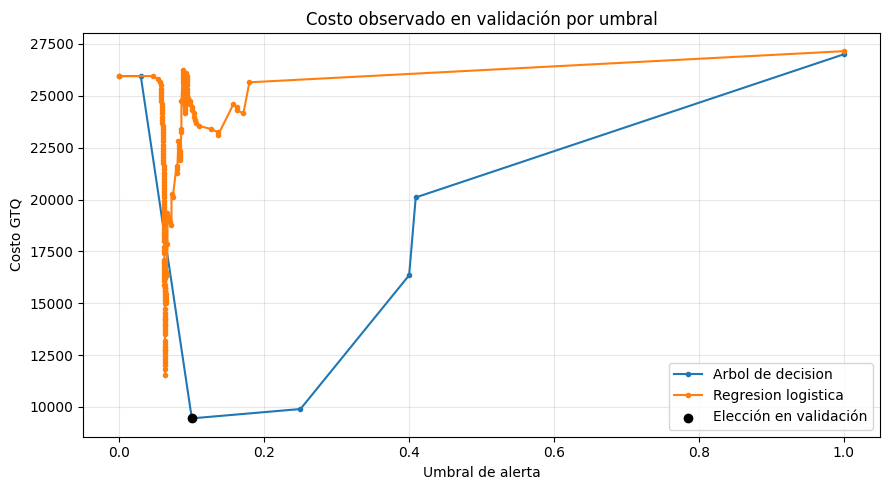

In [18]:
import matplotlib.pyplot as plt

figura_costos, eje_costos = plt.subplots(figsize=(9, 5))

for nombre in tabla_umbrales["modelo"].unique():
    puntos = tabla_umbrales.loc[
        tabla_umbrales["modelo"].eq(nombre)
    ].sort_values("umbral")
    eje_costos.plot(
        puntos["umbral"], puntos["costo_gtq"],
        marker=".", label=nombre
    )

eje_costos.scatter(
    [umbral_elegido], [eleccion["costo_gtq"]],
    color="black", label="Elección en validación", zorder=3
)
eje_costos.set_title("Costo observado en validación por umbral")
eje_costos.set_xlabel("Umbral de alerta")
eje_costos.set_ylabel("Costo GTQ")
eje_costos.legend()
eje_costos.grid(alpha=0.3)
figura_costos.tight_layout()
figura_costos.savefig(
    resultados_dir / "c_costos_umbrales.png",
    dpi=150, bbox_inches="tight"
)
plt.show()


### Evaluación final en prueba

Se aplica el modelo y umbral elegidos sin volver a cambiarlos. Se usa el modelo entrenado, sin ajustarlo con prueba.

El mínimo de validación puede verse mejor de lo que realmente es porque se usó para elegir. Por eso se muestra también el resultado de prueba, que no participó en esa elección.


In [19]:
X_prueba = datos_prueba[columnas_base]
y_prueba = datos_prueba["riesgo_quiebre"]

probabilidad_prueba = modelo_elegido.predict_proba(X_prueba)[:, 1]
alerta_prueba = (probabilidad_prueba >= umbral_elegido).astype(int)

negativos_prueba, falsas_prueba, no_alertados_prueba, detectados_prueba = (
    confusion_matrix(y_prueba, alerta_prueba, labels=[0, 1]).ravel()
)

resultado_prueba = pd.DataFrame({
    "modelo": [nombre_elegido],
    "umbral": [umbral_elegido],
    "filas": [len(datos_prueba)],
    "positivos_reales": [int(y_prueba.sum())],
    "eventos_detectados": [detectados_prueba],
    "eventos_no_alertados": [no_alertados_prueba],
    "falsas_alertas": [falsas_prueba],
    "precision": [precision_score(y_prueba, alerta_prueba, zero_division=0)],
    "recall": [recall_score(y_prueba, alerta_prueba, zero_division=0)],
    "precision_promedio": [average_precision_score(y_prueba, probabilidad_prueba)],
    "costo_gtq": [no_alertados_prueba * 1500 + falsas_prueba * 150]
})
display(resultado_prueba)

referencias_prueba = pd.DataFrame({
    "regla": ["No alertar nunca", "Alertar todo"],
    "costo_gtq": [
        int(y_prueba.sum()) * 1500,
        int(y_prueba.eq(0).sum()) * 150
    ]
})
display(referencias_prueba)

detalle_prueba = datos_prueba[
    ["id_combo", "SKU", "CodigoAlmacen", "riesgo_quiebre"]
].copy()
detalle_prueba["probabilidad"] = probabilidad_prueba
detalle_prueba["alerta"] = alerta_prueba

resultado_prueba.to_csv(resultados_dir / "c_resultado_prueba.csv", index=False)
detalle_prueba.to_csv(resultados_dir / "c_detalle_prueba.csv", index=False)

assert len(detalle_prueba) == len(datos_prueba)
assert detalle_prueba["probabilidad"].between(0, 1).all()


,modelo,umbral,filas,positivos_reales,eventos_detectados,eventos_no_alertados,falsas_alertas,precision,recall,precision_promedio,costo_gtq
0,Arbol de decision,0.1,179,14,11,3,32,0.255814,0.785714,0.248265,9300


,regla,costo_gtq
0,No alertar nunca,21000
1,Alertar todo,24750


### Resultado del paso 4

En validación gana el árbol con umbral 0.10 y costo Q9,450. Detecta 15 eventos, deja 3 sin alertar y genera 33 falsas alertas. La regresión logística llega a Q11,550 con su mejor umbral, cercano a 0.063.

Con la elección fija, en prueba el árbol detecta 11 de 14 eventos y genera 32 falsas alertas. El recall es 78.57% y la precisión 25.58%.

El costo es 3 por Q1,500 más 32 por Q150, igual a Q9,300. No alertar habría costado Q21,000 en esos mismos casos. Esto no garantiza el mismo costo en la entrega o en otra semana.

El umbral 0.10 significa alertar cuando la probabilidad estimada es de 10% o más.


## 5. Confiabilidad y datos que ayudarían

El resultado es una primera referencia con confiabilidad limitada. En prueba se detectaron 11 de 14 eventos, pero solo el 25.58% de las alertas fue correcto. Hay bastantes falsas alertas y pocos positivos para asegurar que estos porcentajes se repitan.

Solo se usó una separación y un corte de datos. No se ha comprobado el resultado en otras semanas ni que las probabilidades coincidan con el riesgo real. Las ventas pueden subestimar demanda si antes faltó producto. Los vacíos de inventario y la falta de movimientos detallados también limitan las variables.

Mejoraría con etiquetas de más semanas, inventario diario completo, fechas de recepción de pedidos y registros de traslados y devoluciones físicas. Esto permitiría validar en el tiempo y distinguir ventas de otros cambios de stock.

También convendría revisar el modelo con nuevos datos antes de usar las alertas para tomar decisiones automáticas. En este trabajo se propone como apoyo para revisión de inventario.


## 6. Predicciones de entrega

Se aplica el árbol ya evaluado con el umbral 0.10 a las 392 combinaciones sin etiqueta. Se mantiene el modelo entrenado con las 546 filas de entrenamiento, sin volver a entrenar con validación o prueba. Así el archivo usa exactamente el modelo evaluado, aunque no aprovecha todas las etiquetas disponibles para ajustar sus reglas.

Se conserva el orden de combos_a_predecir.csv. El archivo de entrega tiene solo id_combo, probabilidad y alerta. La probabilidad no se redondea antes de decidir la alerta. El detalle con SKU y bodega se guarda aparte en resultados/.


In [20]:
X_predecir = variables_predecir[columnas_base]

probabilidades_entrega = modelo_elegido.predict_proba(X_predecir)[:, 1]

predicciones = variables_predecir[["id_combo"]].copy()
predicciones["probabilidad"] = probabilidades_entrega
predicciones["alerta"] = (
    predicciones["probabilidad"] >= umbral_elegido
).astype(int)

assert predicciones.columns.tolist() == ["id_combo", "probabilidad", "alerta"]
assert len(predicciones) == len(combos)
assert predicciones["id_combo"].is_unique
assert predicciones["id_combo"].tolist() == combos["id_combo"].tolist()
assert not predicciones.isna().any().any()
assert predicciones["probabilidad"].between(0, 1).all()
assert predicciones["alerta"].isin([0, 1]).all()

predicciones.to_csv("predicciones.csv", index=False)

detalle_entrega = combos.merge(
    predicciones, on="id_combo", how="left", validate="one_to_one"
)
detalle_entrega.to_csv(
    resultados_dir / "c_predicciones_detalle.csv", index=False
)

print("Modelo:", nombre_elegido)
print("Umbral:", umbral_elegido)
print("Filas de entrega:", len(predicciones))
print("Alertas:", predicciones["alerta"].sum())
display(predicciones.head(10))
display(predicciones["probabilidad"].describe())


Modelo: Arbol de decision
Umbral: 0.1
Filas de entrega: 392
Alertas: 97


,id_combo,probabilidad,alerta
0,C0002,0.409091,1
1,C0003,0.400000,1
2,C0004,0.250000,1
3,C0012,0.029545,0
4,C0013,0.100000,1
5,C0023,0.029545,0
6,C0024,0.029545,0
7,C0034,0.250000,1
8,C0037,0.029545,0
9,C0039,0.250000,1


count    392.000000
mean       0.092573
std        0.122505
min        0.029545
25%        0.029545
50%        0.029545
75%        0.029545
max        0.409091
Name: probabilidad, dtype: float64